# Lake-level perturbations at lake-terminating glaciers (ISSM)

The experiments of Bézu, Nick and Immerzeel (in revision for JGR: Earth Surface), in ISSM: an idealized glacier on two beds, and Luggye Glacier, each first as a flowline and then in plan view. Each glacier is brought to a reference state, the rate and position laws are calibrated to it, and the lake level is then ramped over one year to offsets from −10 to +10 m under each calving law. The icepack version, `lake_terminating_GRL_icepack.ipynb`, has the same structure and choices.

**Sliding laws.** Power law $\tau_b = C|u_b|^{1/m}$; effective pressure $\tau_b = C f_{af}|u_b|^{1/m}$, with the fraction above flotation $f_{af} = (b - z_w + \varrho H)/H$ clamped to [0.01, 1] ($b$ the ice base, $z_w$ the lake level, $\varrho = \rho_i/\rho_w$).

**Calving laws**, for the terminus position $L$: rate law $\dot L = u_t - k\,d_{gl}$; position law $L = \max\{x : f_{af} \geq f^*\}$, reached by advancing with the flow; trivial law $\dot L = 0$. Here $u_t$ is the terminus speed and $d_{gl}$ the water depth at the grounding line. $k$ and $f^*$ are calibrated so that, with the lake level unchanged, the terminus ends the year where it started (within 0.5 m), starting from $k = u_t/d_{gl}$ and $f^* = f_{af}$ at the terminus of the reference glacier.

The plan-view parts need the current `issm_helper` (with `valley_mesh`, `front_diagnostics` and the interpolated front in `diagnostic_solve`).

**Progress** is saved after every run (and in the plan view, every 10 model years of a spin-up and after every calibration try), to a file per section named after its parameters (e.g. `GRL_idealized_3f9a1c2e.npy`). If the kernel stops, rerun the notebook to continue where it left off. Changing a parameter starts a new file, and changing it back picks up the earlier results. Edits to the code are not detected: delete the files after changing the code.

## Imports

In [1]:
import os
import copy
import hashlib
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import tqdm
import geopandas as gpd
import rasterio
import scipy.ndimage
from shapely.ops import substring
from pyproj import Transformer
from types import SimpleNamespace
from matplotlib.tri import Triangulation, LinearTriInterpolator

from model import model
from issm_helper import *
import issm_helper

## Shared parameters

`n_proc` is the number of MPI processes for the plan-view models, at most the cores this session may use; if `mpiexec` cannot start them, `issm_helper` warns and carries on with one. The lake is fresh water; the lake level is at 0 m in the reference state. The ice's rate factor is icepack's, as in the icepack version: it replaces the helper's Cuffey & Paterson (2010) everywhere the helper sets the rheology, and makes the ice 2.1 times softer at 0 °C. Every model has `vertical_layers` evenly spaced layers: on the same glacier, terminus speeds with 5 layers were 3–6% lower than with 20, and with 10 they are within 1%.

In [2]:
T = 273.15 #ice temperature (K)

def icepack_rate_factor(T): #icepack's rate factor (Pa^-3 s^-1)
    T = np.asarray(T, dtype = float)
    A_0 = np.where(T < 263.15, 3.985e-13, 1.916e3) #rate prefactor (s^-1 Pa^-3)
    Q = np.where(T < 263.15, 60e3, 139e3) #activation energy (J mol^-1)
    return A_0*np.exp(-Q/(8.3144621*T))
issm_helper.rate_factor = icepack_rate_factor

m = 3 #Weertman exponent
ρ_w = 1000 #lake water density (kg/m³)
ϱ = model().materials.rho_ice/ρ_w
yts = model().constants.yts

sliding_laws = ['power-law', 'effective-pressure']
calving_laws = ['rate law', 'position law', 'trivial law']
offsets = np.arange(-10, 10 + 1) #lake-level perturbations (m)
ramp_time = 1 #each offset is reached by a linear ramp over one year (a)
vertical_layers = 10 #evenly spaced layers in every model
n_proc = min(8, len(os.sched_getaffinity(0))) #MPI processes for the plan-view models (at most the cores this session may use)

## Sliding laws, depth averages and perturbation runs

ISSM's drag goes as $C^2$, so effective-pressure sliding passes $C\sqrt{f_{af}}$, evaluated from the current geometry and lake level. Speeds are depth-averaged over the (evenly spaced) layers.

`calibrate` finds the value of $k$ or $f^*$ for which the unperturbed run's terminus drift (`drift`, in metres over the year) is within 0.5 m of zero. More calving means more retreat, so the drift decreases as either value grows. After `guess`, the second try is one `step` towards zero drift (more calving if the terminus advanced, less if it retreated); each later try is where the straight line through the last two tries reaches zero drift. Once tries lie on both sides of zero drift, the line is drawn between the closest on either side, and a side that has survived two tries in a row counts half, so that the next try moves away from it (the drift can change abruptly, as calving removes ice in discrete pieces). It stops after 12 tries, or when the closest tries on either side differ by less than `step`/50, and returns the try with the smallest drift. Each try is printed under `name`.

A perturbation run ramps the lake level to its offset and advances the terminus position $L$ by the calving law, as in the icepack version. The ISSM front sits on the node nearest to $L$: with a grounded front inside an element, ISSM largely loses the acceleration of the ice toward the front, so the meshes have 1 m nodes where the front moves. Ice gained by an advance takes the thickness of the old front. `perturbation_run_2d` is the plan-view counterpart, for a model built by `new_model(calving_law)`: the front moves with ISSM's level set under `rate_law` (at $k$ times the local water depth) or `position_law` (where $f_{af} < f^*$), or stays in place, and the run returns the mean length (ice area per unit `width`), the terminus speed, and the flux through the front per unit width (from `front_diagnostics`), after a last stress balance. The terminus speed is the depth-averaged speed where the front meets `paths`, lines down the glacier within 100 m of the centreline (or of the flowline), averaged over them: the speed of the middle of the front, like the flowline's terminus speed. It is not averaged along the whole front, since where the position law cuts a bay into the front, the front grows longer and its average speed falls although the ice in the bay speeds up; nor taken at the centreline alone, which depends on the mesh, since the position law cuts the front back node by node. On the idealized glacier in plan view (power law, no-slip walls, position law, lake 10 m higher), with node lines 10 m apart across the valley instead of 50 m, the terminus speed changed by +4.9 instead of +4.4 m/a (at the centreline alone, +7.5 instead of +2.6 m/a), the mean length by −40.1 instead of −40.4 m and the flux by +582 instead of +527 m²/a.

A run returns the final terminus position, and the terminus speed and grounding-line flux of the final state: after the last step, the velocity is solved once more with the front on its final node, and the flux is the depth-averaged speed times the thickness at the grounding line.

In [3]:
def friction(md, sliding_law, C):
    if sliding_law == 'power-law':
        return C
    H = md.geometry.thickness
    f_af = np.clip((md.geometry.base - md.initialization.sealevel + ϱ*H)/H, 0.01, 1)
    return C*np.sqrt(f_af)

def depth_average(md, field):
    f = np.reshape(field, (md.mesh.numberoflayers, -1))
    return (f[1:] + f[:-1]).mean(axis = 0)/2

def perturbation_run(md, sliding_law, C, calving_law, offset, k, f_star, Δt):
    x = md.mesh.x[:md.mesh.numberofvertices2d]
    H = md.geometry.thickness[:md.mesh.numberofvertices2d]
    L = front = terminus_position(md) #terminus position, and the node the ISSM front sits on (m)

    for step in range(int(round(ramp_time/Δt))):
        waterline = offset*(step + 1)*Δt/ramp_time
        md.initialization.sealevel = waterline*np.ones(md.mesh.numberofvertices)
        set_thickness(md, H)
        md.mask.ice_levelset = md.mesh.x - front

        u = diagnostic_solve(md, friction = friction(md, sliding_law, C))
        H, s = prognostic_solve(md, Δt)

        x_p, ū = profile(md, depth_average(md, u[0]))
        base = profile(md, md.geometry.base)[1]
        thickness = profile(md, md.geometry.thickness)[1]
        x_gl = np.fmin(grounding_line_position(md), front)
        u_t = np.interp(front, x_p, ū)
        d_gl = waterline - np.interp(x_gl, x_p, base)

        if calving_law == 'rate law':
            L += (u_t - k*d_gl)*Δt
        if calving_law == 'position law':
            L += u_t*Δt #advance with the flow, then calve back to where the ice is f* above flotation
            ice = x_p <= front
            f_af = ((base - waterline + ϱ*thickness)/thickness)[ice]
            if f_af[-1] < f_star:
                j = np.flatnonzero(f_af >= f_star)[-1]
                x_i = x_p[ice]
                L = min(L, x_i[j] + (f_af[j] - f_star)/(f_af[j] - f_af[j + 1])*(x_i[j + 1] - x_i[j]))

        new_front = x_p[np.argmin(np.abs(x_p - L))]
        H = np.where((x > front) & (x <= new_front), np.interp(front, x_p, thickness), H)
        front = new_front

    set_thickness(md, H) #the final state, with the front on its final node and the lake at its final level
    md.mask.ice_levelset = md.mesh.x - front
    u = diagnostic_solve(md, friction = friction(md, sliding_law, C))
    x_p, ū = profile(md, depth_average(md, u[0]))
    thickness = profile(md, md.geometry.thickness)[1]
    x_gl = np.fmin(grounding_line_position(md), front)
    return L, np.interp(front, x_p, ū), np.interp(x_gl, x_p, ū)*np.interp(x_gl, x_p, thickness)

def perturbation_run_2d(new_model, sliding_law, C, calving_law, offset, k, f_star, Δt, width, paths):
    md = new_model(calving_law)
    n2 = md.mesh.numberofvertices2d
    bed = md.geometry.bed[:n2]

    for step in range(int(round(ramp_time/Δt))):
        waterline = offset*(step + 1)*Δt/ramp_time
        md.initialization.sealevel = waterline*np.ones(md.mesh.numberofvertices)
        set_thickness(md, md.geometry.thickness) #the geometry in hydrostatic equilibrium with the new lake level
        diagnostic_solve(md, friction = friction(md, sliding_law, C))
        if calving_law == 'rate law':
            rate_law(md, k*np.maximum(waterline - bed, 0)) #at k times the local water depth
        if calving_law == 'position law':
            H, base = md.geometry.thickness[:n2], md.geometry.base[:n2]
            position_law(md, forcing = -(base - waterline + ϱ*H)/H, threshold = -f_star) #calve where f_af < f*
        prognostic_solve(md, Δt)

    set_thickness(md, md.geometry.thickness)
    u = diagnostic_solve(md, friction = friction(md, sliding_law, C)) #the final state
    front = front_diagnostics(md)
    return front.area/width, speed_at_front(md, u, paths), front.flux/width

def speed_at_front(md, u, paths): #depth-averaged speed (m/a) where paths down the glacier first leave the ice, averaged over the paths
    n2 = md.mesh.numberofvertices2d
    triangles = Triangulation(md.mesh.x[:n2], md.mesh.y[:n2], md.mesh.elements2d - 1)
    φ_at = LinearTriInterpolator(triangles, md.mask.ice_levelset[:n2])
    speed_at = LinearTriInterpolator(triangles, np.hypot(depth_average(md, u[0]), depth_average(md, u[1])))
    speeds = []
    for path in paths:
        φ, speed = φ_at(*path.T).filled(np.nan), speed_at(*path.T).filled(np.nan)
        i = np.flatnonzero((φ[:-1] <= 0) & (φ[1:] > 0)) #the last points in the ice
        if i.size:
            i = i[0]
            speeds.append(speed[i] + (speed[i + 1] - speed[i])*(0 - φ[i])/(φ[i + 1] - φ[i]))
    return np.mean(speeds)

def remembered(drift, tries, save): #drift, keeping each try in tries and saving them, so that a restarted calibration replays its tries
    def known_drift(value):
        if value not in tries:
            tries[value] = drift(value)
            save()
        return tries[value]
    return known_drift

def calibrate(drift, guess, step, name):
    tries = {}
    value, move, sides = guess, step, []
    for attempt in range(12):
        tries[value] = drift(value)
        print(f'{name} = {value:.4f}: terminus drift {tries[value]:+.2f} m')
        if abs(tries[value]) < 0.5:
            break
        advanced = [v for v in tries if tries[v] > 0] #too little calving: the terminus advanced
        retreated = [v for v in tries if tries[v] < 0] #too much: it retreated
        if advanced and retreated: #zero drift lies between the closest tries on either side
            low, high = max(advanced), min(retreated)
            if high - low < step/50:
                break
            sides.append(np.sign(tries[value]))
            d_low = tries[low]/2 if sides[-2:] == [-1, -1] else tries[low] #a side that survived the last two tries counts half,
            d_high = tries[high]/2 if sides[-2:] == [1, 1] else tries[high] #so the next try moves away from it
            value = low + (high - low)*d_low/(d_low - d_high) #where the straight line between them reaches zero drift
        else: #not there yet: follow the straight line through the last two tries, at most four times as far as the last move
            if len(tries) > 1:
                previous = list(tries)[-2]
                line = abs(tries[value]*(value - previous)/(tries[value] - tries[previous])) if tries[value] != tries[previous] else np.inf
                move = min(line, 4*move)
            value = value + move*np.sign(tries[value]) #more calving if the terminus advanced, less if it retreated
    best = min(tries, key = lambda v: abs(tries[v]))
    return best, tries[best]

# Idealized glacier (flowline)

## Parameters

A 5 km glacier on a 5% prograde bed, in a lake 50 m deep. $C$ is icepack's 0.2 MPa (m/a)$^{-1/3}$ in ISSM's convention, $\tau_b = C^2|u_b|^{1/m}$.

In [4]:
L_0 = 5000 #initial glacier length (m)
H_0 = 200 #initial ice thickness (m)
slope = 0.05 #mean bed slope, prograde
d_0 = 50 #lake depth at the terminus (m)
D_b, L_b = 50, 1000 #depth and length of the trough behind the retrograde terminus (m)
C = np.sqrt(0.2e6*yts**(1/m)) #Weertman C
u_in = 10 #inflow speed at the head (m/a)

directions = ['retrograde', 'prograde'] #bed slope just upstream of the terminus
Δt_spinup = 0.5 #spin-up time step (a)
max_spinup = 400 #longest spin-up (a)
Δt = 0.1 #perturbation time step (a)

## Geometry

The prograde bed is a plane sloping down to the lake. The retrograde bed is the same plane with a smooth trough just behind the terminus: one cosine dip, `L_b` long and `D_b` deep at its centre (relative to the plane), ending at the terminus, so the lake depth at the terminus is unchanged and the two directions differ only upstream. The surface starts smooth, so the ice is thicker over the trough. Beyond the terminus the lake floor stays level. Nodes are 1 m apart where the front moves, and 50 m elsewhere.

In [5]:
x_nodes = np.unique(np.r_[np.arange(0, 4800, 50), np.arange(4800, 4880, 5), np.arange(4880, 5040, 1),
                          np.arange(5040, 5100, 5), np.arange(5100, 7000 + 1, 50)]) #node positions, with 2 km of lake beyond the glacier (m)
md = flowline_mesh(model(), x_nodes)
x = md.mesh.x

s_t = np.maximum(L_0 - x, 0) #distance upstream of the terminus (m)
plane = -d_0 + slope*s_t #the prograde bed
trough = np.where(s_t < L_b, D_b*(1 - np.cos(2*np.pi*s_t/L_b))/2, 0) #the cosine dip behind the retrograde terminus
beds = {'retrograde': plane - trough, 'prograde': plane}
thicknesses = {direction: plane + H_0 - bed for direction, bed in beds.items()}

params = {'approximation': 'HO',
          'vertical_layers': vertical_layers,
          'temperature': T,
          'friction': C, #replaced by friction(md, sliding_law, C) at every solve
          'm': m,
          'rho_water': ρ_w,
          'ice_levelset': x - L_0,
          'spcvx': dirichlet(md, (x == 0, u_in)),
          'spcthickness': dirichlet(md, (x == 0, H_0))}

## Spin-up and calibration

The trivial law (fixed front), until the ice volume changes by less than $10^{-5}$ per year, for at most `max_spinup` years. The terminus is grounded, so $d_{gl}$ is the water depth at the terminus. Then $k$ and $f^*$ are calibrated for zero terminus drift.

In [6]:
settings = {'calibration': 'zero drift', 'flux': 'at the final position', 'vertical_layers': vertical_layers, 'T': T, 'A': float(issm_helper.rate_factor(T)), 'm': m, 'ρ_w': ρ_w, 'offsets': offsets.tolist(), 'ramp_time': ramp_time,
            'L_0': L_0, 'H_0': H_0, 'slope': slope, 'd_0': d_0, 'D_b': D_b, 'L_b': L_b, 'C': C, 'u_in': u_in,
            'Δt_spinup': Δt_spinup, 'max_spinup': max_spinup, 'Δt': Δt, 'x_nodes': x_nodes.tolist()} #everything the results depend on
save_file = f'GRL_idealized_{hashlib.md5(str(settings).encode()).hexdigest()[:8]}.npy'
saved = np.load(save_file, allow_pickle = True).item() if os.path.exists(save_file) else {}
print('progress file:', save_file)

for sliding_law in sliding_laws:
    for direction in directions:
        if (sliding_law, direction) in saved:
            continue
        md = flowline_mesh(model(), x_nodes)
        md = initialize_model(md, moving_front = False, bed = beds[direction], thickness = thicknesses[direction], **params)

        V = ice_volume(md)
        for step in tqdm.trange(int(round(max_spinup/Δt_spinup)), desc = f'{sliding_law}, {direction} (steps of {Δt_spinup} a)'):
            u, H, s = coupled_solve(md, Δt_spinup, friction = friction(md, sliding_law, C))
            V, V_old = ice_volume(md), V
            if abs(V - V_old)/V/Δt_spinup < 1e-5:
                break
        years = (step + 1)*Δt_spinup

        x_p, ū = profile(md, depth_average(md, u[0]))
        u_t = np.interp(L_0, x_p, ū)
        base_t = np.interp(L_0, *profile(md, md.geometry.base))
        H_t = np.interp(L_0, *profile(md, md.geometry.thickness))
        k_0, f_0 = u_t/(0 - base_t), (base_t - 0 + ϱ*H_t)/H_t

        def drift(calving_law, k, f_star): #how far the terminus moves in the unperturbed run (m)
            md = flowline_mesh(model(), x_nodes)
            md = initialize_model(md, moving_front = False, bed = beds[direction], thickness = H, **params)
            return perturbation_run(md, sliding_law, C, calving_law, 0, k, f_star, Δt)[0] - L_0
        k, drift_k = calibrate(lambda k: drift('rate law', k, None), k_0, 0.05*k_0, f'{sliding_law}, {direction}: k')
        f_star, drift_f = calibrate(lambda f_star: drift('position law', None, f_star), f_0, 0.005, f'{sliding_law}, {direction}: f*')
        saved[(sliding_law, direction)] = {'years': years, 'H': H, 'k': k, 'f_star': f_star, 'k_0': k_0, 'f_0': f_0, 'drift_k': drift_k, 'drift_f': drift_f}
        np.save(save_file, saved)

for sliding_law in sliding_laws:
    for direction in directions:
        c = saved[(sliding_law, direction)]
        steady = f'steady after {c["years"]:.0f} a' if c['years'] < max_spinup else f'NOT steady after {max_spinup} a'
        print(f'{sliding_law}, {direction}: {steady}; k = {c["k_0"]:.3f} -> {c["k"]:.3f} /a (terminus drift {c["drift_k"]:+.2f} m), '
              f'f* = {c["f_0"]:.3f} -> {c["f_star"]:.3f} ({c["drift_f"]:+.2f} m)')

progress file: GRL_idealized_aacdbe57.npy
power-law, retrograde: steady after 208 a; k = 0.565 -> 0.565 /a (terminus drift -0.00 m), f* = 0.212 -> 0.212 (-0.01 m)
power-law, prograde: steady after 210 a; k = 0.566 -> 0.566 /a (terminus drift -0.00 m), f* = 0.208 -> 0.208 (-0.01 m)
effective-pressure, retrograde: steady after 213 a; k = 0.583 -> 0.583 /a (terminus drift -0.00 m), f* = 0.191 -> 0.191 (-0.01 m)
effective-pressure, prograde: steady after 214 a; k = 0.589 -> 0.589 /a (terminus drift -0.00 m), f* = 0.180 -> 0.180 (-0.01 m)


## Figure 1: the spun-up glaciers

With the depth-averaged speed in red (right axis). The dashed line is the terminus, the triangle the grounding line.

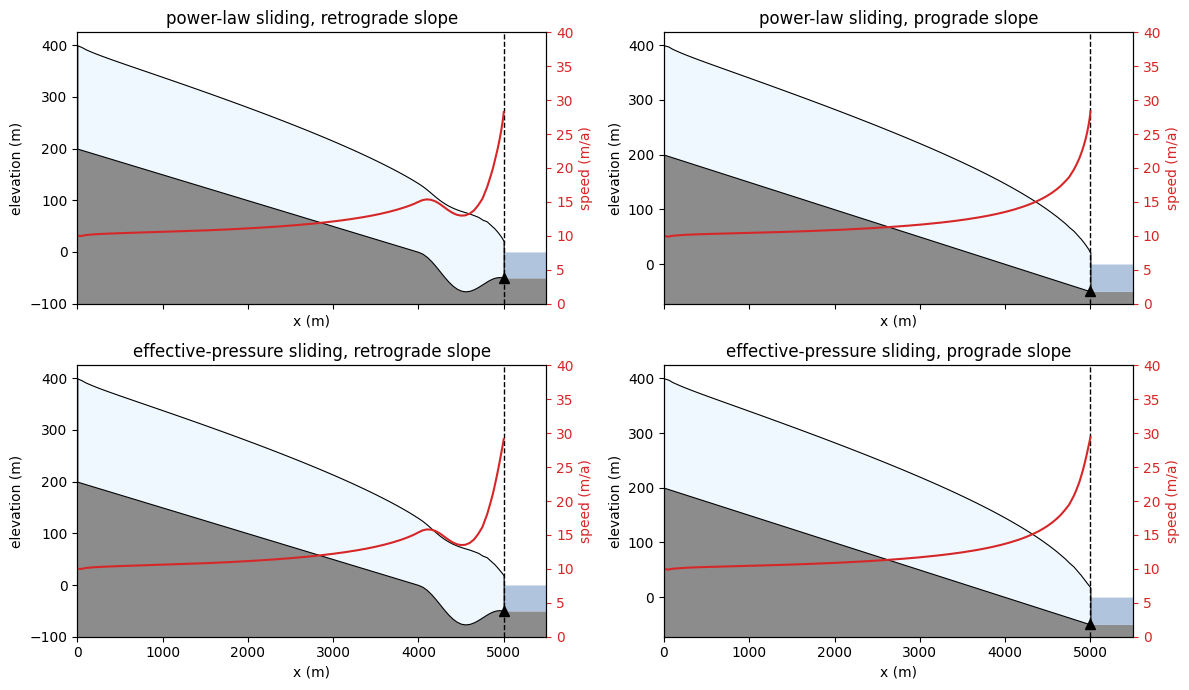

In [7]:
fig, axes = plt.subplots(2, 2, figsize = (12, 7), sharex = True)
for i, sliding_law in enumerate(sliding_laws):
    for j, direction in enumerate(directions):
        md = flowline_mesh(model(), x_nodes)
        md = initialize_model(md, moving_front = False, bed = beds[direction], thickness = saved[(sliding_law, direction)]['H'], **params)
        u = diagnostic_solve(md, friction = friction(md, sliding_law, C))

        ax = axes[i, j]
        plot_geometry(md, ax = ax, title = f'{sliding_law} sliding, {direction} slope')
        ax.set_xlim(0, L_0 + 500)
        x_p, speed = profile(md, depth_average(md, u[0]))
        ice = x_p <= L_0
        ax2 = ax.twinx()
        ax2.plot(x_p[ice], speed[ice], color = 'C3')
        ax2.set_ylim(0, 40)
        ax2.set_ylabel('speed (m/a)', color = 'C3')
        ax2.tick_params(axis = 'y', colors = 'C3')
plt.tight_layout()
plt.show()

## Lake-level perturbations

Each run starts from the spun-up glacier.

In [8]:
for sliding_law in sliding_laws:
    for direction in directions:
        for calving_law in calving_laws:
            r = saved.setdefault((sliding_law, direction, calving_law), {'L': [], 'u_t': [], 'flux': []})
            for offset in tqdm.tqdm(offsets[len(r['L']):], desc = f'{sliding_law}, {direction}, {calving_law}'):
                spinup = saved[(sliding_law, direction)]
                md = flowline_mesh(model(), x_nodes)
                md = initialize_model(md, moving_front = False, bed = beds[direction], thickness = spinup['H'], **params)
                L, u_t, flux = perturbation_run(md, sliding_law, C, calving_law, offset, spinup['k'], spinup['f_star'], Δt)
                r['L'].append(L)
                r['u_t'].append(u_t)
                r['flux'].append(flux)
                np.save(save_file, saved)

power-law, retrograde, rate law: 0it [00:00, ?it/s]

power-law, retrograde, rate law: 0it [00:00, ?it/s]

power-law, retrograde, position law: 0it [00:00, ?it/s]

power-law, retrograde, position law: 0it [00:00, ?it/s]

power-law, retrograde, trivial law: 0it [00:00, ?it/s]

...

effective-pressure, prograde, rate law: 0it [00:00, ?it/s]

effective-pressure, prograde, position law: 0it [00:00, ?it/s]

effective-pressure, prograde, position law: 0it [00:00, ?it/s]

effective-pressure, prograde, trivial law: 0it [00:00, ?it/s]

effective-pressure, prograde, trivial law: 0it [00:00, ?it/s]

## Figure 2: response to the lake level

Changes relative to the unperturbed run. Colour is the sliding law; downward triangles are the retrograde bed and upward triangles the prograde bed, overlapping as stars where the two agree.

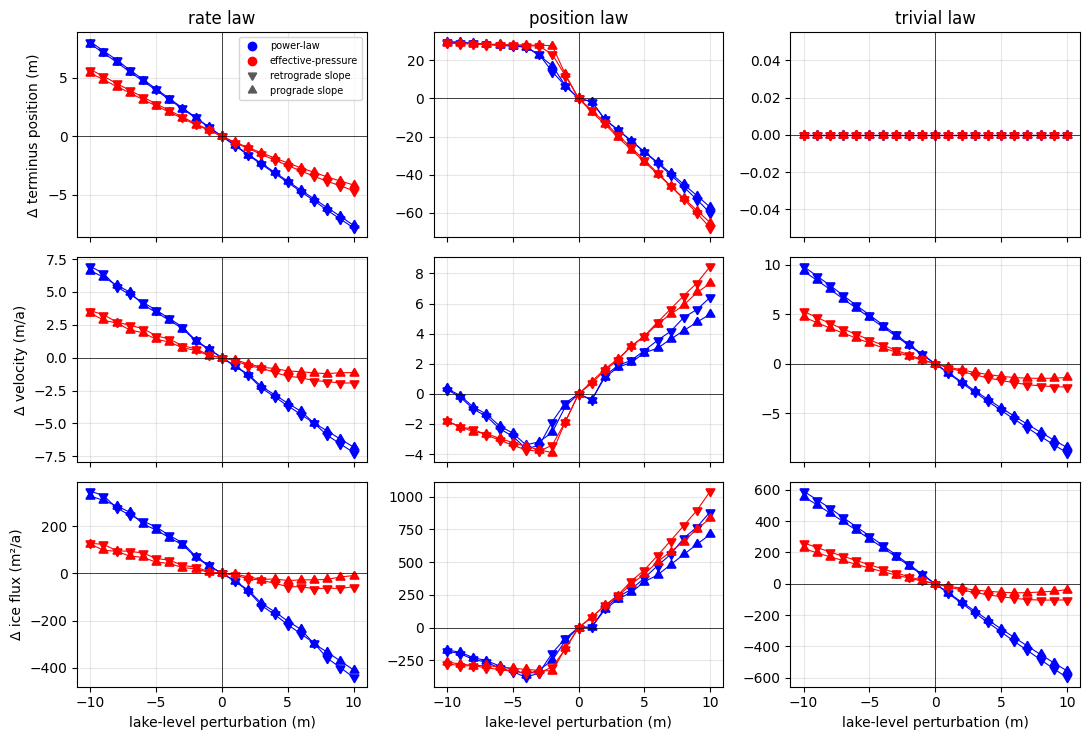

In [9]:
colors = {'power-law': 'blue', 'effective-pressure': 'red'}
markers = {'retrograde': (3, 0, 180), 'prograde': (3, 0, 0)}

fig, axes = plt.subplots(3, 3, figsize = (11, 7.5), sharex = True)
for j, calving_law in enumerate(calving_laws):
    for sliding_law in sliding_laws:
        for direction in directions:
            r = saved[(sliding_law, direction, calving_law)]
            for i, key in enumerate(['L', 'u_t', 'flux']):
                y = np.array(r[key])
                axes[i, j].plot(offsets, y - y[offsets == 0], color = colors[sliding_law],
                                marker = markers[direction], markersize = 7.5, linewidth = 0.8)
    axes[0, j].set_title(calving_law)
    axes[2, j].set_xlabel('lake-level perturbation (m)')
for i, label in enumerate(['Δ terminus position (m)', 'Δ velocity (m/a)', 'Δ ice flux (m²/a)']):
    axes[i, 0].set_ylabel(label)
for ax in axes.ravel():
    ax.axhline(0, color = 'k', linewidth = 0.5)
    ax.axvline(0, color = 'k', linewidth = 0.5)
    ax.grid(alpha = 0.3)
handles = [Line2D([], [], color = colors[s], marker = 'o', linewidth = 0, label = s) for s in sliding_laws]
handles += [Line2D([], [], color = '0.35', marker = markers[d], markersize = 7, linewidth = 0, label = f'{d} slope') for d in directions]
axes[0, 0].legend(handles = handles, fontsize = 7)
plt.tight_layout()
plt.show()

# Idealized glacier in plan view: buttressing by the valley walls

The retrograde glacier in a valley 500 m wide, in two versions that differ only in how the ice meets the valley walls: frozen to them (no slip), so that the walls hold the glacier back through lateral drag, or sliding freely along them (free slip: the ice cannot flow through the walls, but nothing resists its flow along them). Comparing the two isolates the buttressing that the lateral stresses provide, which a flowline model cannot represent, and how it shapes the response to the lake level. Along the centreline, the valley floor is the flowline bed with the trough behind the terminus; across the valley it rises by `D_v` towards the walls as a parabola, and the walls themselves are vertical. The ice enters at 10 m/a across the head of the valley, and the lake fills the valley beyond the terminus.

The model is the same HO model with the same 10 layers, but the front now spans the valley and moves with ISSM's level set, under the same calving laws applied locally through `issm_helper`'s `rate_law` and `position_law`: the rate law calves at $k$ times the local water depth, normal to the front, and the position law removes the ice wherever $f_{af} < f^*$, working back from the front. The trivial law keeps the front in place. Where the front runs through elements, `issm_helper` solves the stress balance with the front on the vertices just behind and just ahead of it and interpolates between the two (see `diagnostic_solve`), so the velocity changes smoothly as the front moves.

The diagnostics are those of the whole front, at the end of each run: the mean glacier length (ice area divided by the valley width), the terminus speed (the depth-averaged speed of the front within 100 m of the centreline, as for the flowline's terminus), and the flux through the front per unit width (`front_diagnostics`).

The plan-view models run on `n_proc` MPI processes and need ISSM built with MUMPS (on a single process without MUMPS, `issm_helper` falls back to PETSc's serial direct solver, which works but is slow). With 8 processes on Snellius, the earlier version of this part (four glaciers, as here, spun up for 400 years) took about 9 hours; with spin-ups of up to 1000 years, this one may take up to about 12. Progress is saved as it goes.

## Parameters

The valley width, the rise of its floor towards the walls, and the two wall conditions. The vertices are 5 m apart along the valley where the front can move, 100 m apart far upstream, and across the valley from 50 m in the middle to 10 m at the walls, where the ice shears most; with 15 rows across, the flux at the front is within 1% of that with 31.

In [10]:
W = 500 #valley width (m)
D_v = 40 #rise of the valley floor from the centreline to the walls (m)

x_nodes_2d = np.unique(np.r_[np.arange(0, 4500, 100), np.arange(4500, 4850, 50), np.arange(4850, 5080, 5),
                             np.arange(5080, 5200, 20), np.arange(5200, 5500 + 1, 50)]) #along the valley, with 500 m of lake (m)
y_half = np.array([0, 50, 100, 150, 190, 220, 240, 250])
y_nodes_2d = np.unique(np.r_[-y_half, y_half]) #across the valley (m)
walls_2d = ['no slip', 'free slip'] #how the ice meets the valley walls
max_spinup_2d = 1000 #longest plan-view spin-up (a): the plan-view glaciers settle more slowly than the flowline (with no-slip walls, the volume still changed by 3e-5 per year after 400 a)
offsets_2d = offsets #lake-level perturbations in plan view (m); every other one, offsets[::2], saves a third of the time
paths_2d = [np.c_[np.arange(0, x_nodes_2d[-1] + 1), np.full(int(x_nodes_2d[-1]) + 1, y_0)] for y_0 in np.arange(-100, 101, 10)] #lines along the valley within 100 m of the centreline, every metre: the terminus speed is averaged over where they meet the front

## Geometry

`new_model_2d` builds a plan-view model of the glacier with either wall condition from a thickness field, with the front fixed (trivial law) or moving, and an initial guess for the velocity (the depth-averaged velocity of the reference state, which saves the stress balance many iterations). On the walls, both velocity components are zero for no slip; for free slip, only the component across the valley is, and the flow along the walls is free.

In [11]:
md = valley_mesh(model(), x_nodes_2d, y_nodes_2d)
x2, y2 = md.mesh.x, md.mesh.y
s_t2 = np.maximum(L_0 - x2, 0) #distance upstream of the terminus (m)
plane2 = -d_0 + slope*s_t2
trough2 = np.where(s_t2 < L_b, D_b*(1 - np.cos(2*np.pi*s_t2/L_b))/2, 0)
valley2 = D_v*(2*y2/W)**2
bed_2d = plane2 - trough2 + valley2 #the retrograde bed, rising towards the walls

on_walls = np.isclose(np.abs(y2), W/2)
params_2d = {'approximation': 'HO',
             'vertical_layers': vertical_layers,
             'temperature': T,
             'friction': C,
             'm': m,
             'rho_water': ρ_w,
             'ice_levelset': x2 - L_0}
spcv_2d = {'no slip': (dirichlet(md, (x2 == 0, u_in), (on_walls, 0)), dirichlet(md, (on_walls | (x2 == 0), 0))),
           'free slip': (dirichlet(md, (x2 == 0, u_in)), dirichlet(md, (on_walls | (x2 == 0), 0)))} #(spcvx, spcvy) for each wall condition

def new_model_2d(wall, H, calving_law, velocity = (0, 0)):
    md = valley_mesh(model(), x_nodes_2d, y_nodes_2d)
    md.cluster.np = n_proc
    spcvx, spcvy = spcv_2d[wall]
    return initialize_model(md, bed = bed_2d, thickness = H, moving_front = calving_law != 'trivial law', velocity = velocity,
                            spcvx = spcvx, spcvy = spcvy, spcthickness = dirichlet(md, (x2 == 0, H)), **params_2d)

## Spin-up and calibration

Both versions of each glacier start from the same geometry, the spun-up flowline glacier's surface (retrograde bed) flat across the valley, and each is spun up with its own walls and the front fixed until the ice volume changes by less than $10^{-5}$ per year, for at most `max_spinup_2d` years. The spin-up is saved every 10 model years and each calibration try as it is made, so a restart carries on from there. $k$ and $f^*$ are then calibrated for zero drift of the mean length over the unperturbed year, starting from $k$ = mean speed at the front / mean water depth there and $f^*$ = the lowest $f_{af}$ along the front (where the position law would calve first).

In [12]:
settings_2d = {'flowline': settings, 'bed': 'retrograde', 'walls': walls_2d, 'max_spinup_2d': max_spinup_2d, 'W': W, 'D_v': D_v, 'x_nodes_2d': x_nodes_2d.tolist(),
               'y_nodes_2d': y_nodes_2d.tolist(), 'offsets_2d': np.asarray(offsets_2d).tolist()} #everything the results depend on
save_file_2d = f'GRL_idealized_2d_{hashlib.md5(str(settings_2d).encode()).hexdigest()[:8]}.npy'
saved_2d = np.load(save_file_2d, allow_pickle = True).item() if os.path.exists(save_file_2d) else {}
print('progress file:', save_file_2d)

md_fl = flowline_mesh(model(), x_nodes)
save_2d = lambda: np.save(save_file_2d, saved_2d)
n_spinup = int(round(max_spinup_2d/Δt_spinup))
for sliding_law in sliding_laws:
    for wall in walls_2d:
        if (sliding_law, wall) in saved_2d:
            continue
        #the spin-up so far, or else the spun-up flowline glacier (grounded everywhere) with its surface flat across the valley
        state = saved_2d.get(('spin-up', sliding_law, wall))
        if state is None:
            x_s, surface = profile(md_fl, beds['retrograde'] + saved[(sliding_law, 'retrograde')]['H'])
            state = {'H': np.maximum(np.interp(x2, x_s, surface) - bed_2d, 1), 'velocity': (0, 0), 'steps': 0, 'done': False}
        md = new_model_2d(wall, state['H'], 'trivial law', state['velocity'])
        V = ice_volume(md)
        for step in ([] if state['done'] else tqdm.trange(state['steps'], n_spinup, initial = state['steps'], total = n_spinup,
                                                            desc = f'{sliding_law}, {wall} (steps of {Δt_spinup} a)')):
            u, H, s = coupled_solve(md, Δt_spinup, friction = friction(md, sliding_law, C))
            V, V_old = ice_volume(md), V
            volume_change = abs(V - V_old)/V/Δt_spinup #relative change per year
            state = {'H': H, 'velocity': (depth_average(md, u[0]), depth_average(md, u[1])), 'steps': step + 1, 'volume_change': volume_change,
                     'done': volume_change < 1e-5 or step + 1 == n_spinup}
            if state['done'] or (step + 1) % 20 == 0: #every 10 years, so that a restart carries on from here
                saved_2d[('spin-up', sliding_law, wall)] = state
                save_2d()
            if state['done']:
                break
        years = state['steps']*Δt_spinup

        #the reference state's front, the starting guesses and every calibration try, kept so that a restart replays them
        reference = saved_2d.setdefault(('reference', sliding_law, wall), {})
        if 'k_0' not in reference:
            u = diagnostic_solve(md, friction = friction(md, sliding_law, C))
            f = front_diagnostics(md)
            n2 = md.mesh.numberofvertices2d
            on_front = np.isclose(md.mesh.x[:n2], L_0)
            order = np.argsort(md.mesh.y[:n2][on_front])
            y_f, b_f, H_f = md.mesh.y[:n2][on_front][order], md.geometry.base[:n2][on_front][order], md.geometry.thickness[:n2][on_front][order]
            depth = np.sum((-b_f[1:] - b_f[:-1])/2*np.diff(y_f))/W #mean water depth along the front
            reference.update({'velocity': (depth_average(md, u[0]), depth_average(md, u[1])), 'length': f.area/W,
                              'k_0': f.speed/depth, 'f_0': np.min((b_f - 0 + ϱ*H_f)/H_f), #f_0 where the position law would calve first
                              'k tries': {}, 'f* tries': {}})
            save_2d()
        H, velocity = state['H'], reference['velocity']

        def drift(calving_law, k, f_star): #how far the mean length changes in the unperturbed run (m)
            run = perturbation_run_2d(lambda law: new_model_2d(wall, H, law, velocity), sliding_law, C, calving_law, 0, k, f_star, Δt, W, paths_2d)
            return run[0] - reference['length']
        k, drift_k = calibrate(remembered(lambda k: drift('rate law', k, None), reference['k tries'], save_2d),
                               reference['k_0'], 0.05*reference['k_0'], f'{sliding_law}, {wall}: k')
        f_star, drift_f = calibrate(remembered(lambda f_star: drift('position law', None, f_star), reference['f* tries'], save_2d),
                                    reference['f_0'], 0.005, f'{sliding_law}, {wall}: f*')
        saved_2d[(sliding_law, wall)] = {'years': years, 'volume_change': state['volume_change'], 'H': H, 'velocity': velocity,
                                              'length': reference['length'], 'k': k, 'f_star': f_star, 'k_0': reference['k_0'], 'f_0': reference['f_0'],
                                              'drift_k': drift_k, 'drift_f': drift_f}
        save_2d()

for sliding_law in sliding_laws:
    for wall in walls_2d:
        c = saved_2d[(sliding_law, wall)]
        steady = f'steady after {c["years"]:.0f} a' if c['years'] < max_spinup_2d else f'NOT steady after {max_spinup_2d} a (volume changing by {c["volume_change"]:.1e} per year)'
        print(f'{sliding_law}, {wall}: {steady}; k = {c["k_0"]:.3f} -> {c["k"]:.3f} /a (drift {c["drift_k"]:+.2f} m), '
              f'f* = {c["f_0"]:.3f} -> {c["f_star"]:.3f} ({c["drift_f"]:+.2f} m)')

progress file: GRL_idealized_2d_0a51419a.npy


power-law, no slip (steps of 0.5 a):   0%|          | 0/2000 [00:00<?, ?it/s]

power-law, no slip (steps of 0.5 a):   0%|          | 1/2000 [00:06<3:43:12,  6.70s/it]

power-law, no slip (steps of 0.5 a):   0%|          | 2/2000 [00:10<2:37:10,  4.72s/it]

power-law, no slip (steps of 0.5 a):   0%|          | 3/2000 [00:13<2:15:57,  4.08s/it]

...

effective-pressure, free slip: f* = 0.2438: terminus drift +10.94 m


effective-pressure, free slip: f* = 0.3028: terminus drift -8.31 m


effective-pressure, free slip: f* = 0.2773: terminus drift +2.07 m


effective-pressure, free slip: f* = 0.2824: terminus drift -1.22 m


effective-pressure, free slip: f* = 0.2805: terminus drift -0.12 m
power-law, no slip: steady after 482 a; k = 0.611 -> 0.580 /a (drift -0.21 m), f* = 0.226 -> 0.272 (+0.83 m)
power-law, free slip: steady after 227 a; k = 0.773 -> 0.735 /a (drift +0.26 m), f* = 0.234 -> 0.294 (+0.03 m)
effective-pressure, no slip: steady after 486 a; k = 0.627 -> 0.596 /a (drift +0.03 m), f* = 0.208 -> 0.256 (+0.29 m)
effective-pressure, free slip: steady after 230 a; k = 0.790 -> 0.751 /a (drift +0.25 m), f* = 0.219 -> 0.281 (-0.12 m)


## Figure 4: the spun-up glaciers in plan view

The depth-averaged speed over the lowest 1.5 km of each glacier, with no-slip walls (left) and free-slip walls (right), and the front in black.

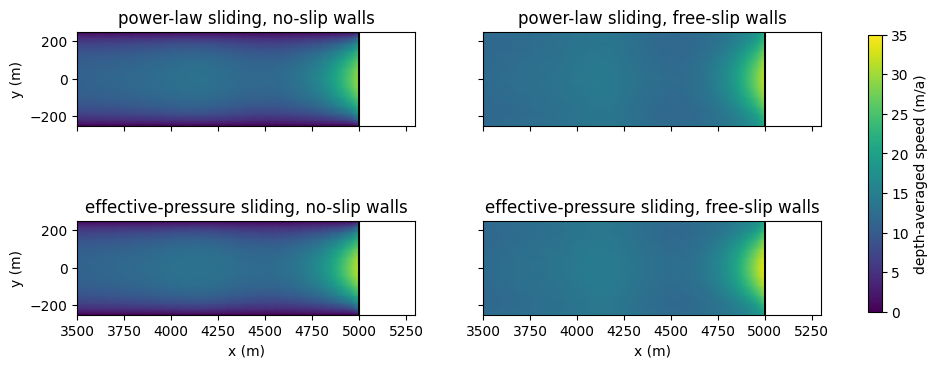

In [13]:
speeds = {}
for sliding_law in sliding_laws:
    for wall in walls_2d:
        spinup = saved_2d[(sliding_law, wall)]
        md = new_model_2d(wall, spinup['H'], 'trivial law', spinup['velocity'])
        u = diagnostic_solve(md, friction = friction(md, sliding_law, C))
        speeds[(sliding_law, wall)] = np.hypot(depth_average(md, u[0]), depth_average(md, u[1]))
n2 = md.mesh.numberofvertices2d
x_2, y_2, φ_2, elements = md.mesh.x[:n2], md.mesh.y[:n2], md.mask.ice_levelset[:n2], md.mesh.elements2d - 1
ice = np.max(φ_2[elements], axis = 1) <= 0
v_max = 5*np.ceil(max(speed[x_2 >= L_0 - 1500].max() for speed in speeds.values())/5)

fig, axes = plt.subplots(len(sliding_laws), len(walls_2d), figsize = (12, 2.25*len(sliding_laws)), sharex = True, sharey = True, squeeze = False)
for i, sliding_law in enumerate(sliding_laws):
    for j, wall in enumerate(walls_2d):
        ax = axes[i, j]
        image = ax.tripcolor(x_2, y_2, elements[ice], speeds[(sliding_law, wall)], shading = 'gouraud', vmin = 0, vmax = v_max, cmap = 'viridis')
        ax.tricontour(x_2, y_2, elements, φ_2, levels = [0], colors = 'k', linewidths = 1.5)
        ax.set_xlim(L_0 - 1500, L_0 + 300)
        ax.set_aspect('equal')
        ax.set_title(f'{sliding_law} sliding, {wall.replace(" ", "-")} walls')
for ax in axes[-1]:
    ax.set_xlabel('x (m)')
for ax in axes[:, 0]:
    ax.set_ylabel('y (m)')
fig.colorbar(image, ax = axes, label = 'depth-averaged speed (m/a)', shrink = 0.8)
plt.show()

## Lake-level perturbations in plan view

Each run starts from the spun-up glacier; progress is saved after every run.

In [14]:
for sliding_law in sliding_laws:
    for wall in walls_2d:
        spinup = saved_2d[(sliding_law, wall)]
        for calving_law in calving_laws:
            r = saved_2d.setdefault((sliding_law, wall, calving_law), {'L': [], 'u_t': [], 'flux': []})
            for offset in tqdm.tqdm(offsets_2d[len(r['L']):], desc = f'{sliding_law}, {wall}, {calving_law}'):
                L, u_t, flux = perturbation_run_2d(lambda law: new_model_2d(wall, spinup['H'], law, spinup['velocity']), sliding_law, C, calving_law,
                                                   offset, spinup['k'], spinup['f_star'], Δt, W, paths_2d)
                r['L'].append(L)
                r['u_t'].append(u_t)
                r['flux'].append(flux)
                np.save(save_file_2d, saved_2d)

power-law, no slip, rate law:   0%|          | 0/21 [00:00<?, ?it/s]

power-law, no slip, rate law:   5%|▍         | 1/21 [01:40<33:37, 100.88s/it]

power-law, no slip, rate law:  10%|▉         | 2/21 [03:21<31:48, 100.44s/it]

power-law, no slip, rate law:  14%|█▍        | 3/21 [05:00<29:59, 99.98s/it] 

power-law, no slip, rate law:  19%|█▉        | 4/21 [06:39<28:15, 99.74s/it]

...

effective-pressure, free slip, trivial law:  86%|████████▌ | 18/21 [15:35<02:40, 53.64s/it]

effective-pressure, free slip, trivial law:  90%|█████████ | 19/21 [16:33<01:50, 55.00s/it]

effective-pressure, free slip, trivial law:  95%|█████████▌| 20/21 [17:31<00:56, 56.05s/it]

effective-pressure, free slip, trivial law: 100%|██████████| 21/21 [18:30<00:00, 56.84s/it]

effective-pressure, free slip, trivial law: 100%|██████████| 21/21 [18:30<00:00, 52.88s/it]

## Figure 5: response to the lake level, with and without buttressing by the walls

Changes relative to the unperturbed run, with no-slip walls (filled markers, solid) and free-slip walls (open markers, dashed). Velocity is the terminus speed (the mean over the front within 100 m of the centreline); the flux is per unit width of the valley.

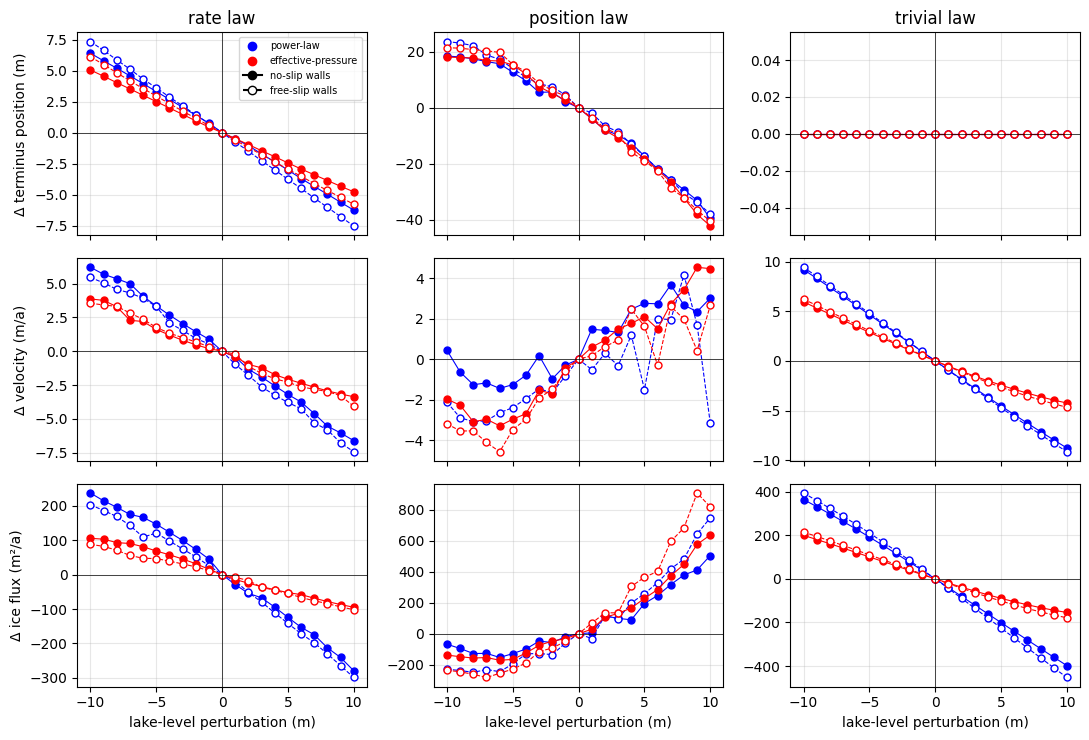

In [15]:
fig, axes = plt.subplots(3, 3, figsize = (11, 7.5), sharex = True)
for j, calving_law in enumerate(calving_laws):
    for sliding_law in sliding_laws:
        for wall, style in [('no slip', dict(linestyle = 'solid')), ('free slip', dict(linestyle = 'dashed', markerfacecolor = 'white'))]:
            r = saved_2d[(sliding_law, wall, calving_law)]
            x_off = np.asarray(offsets_2d)
            for i, key in enumerate(['L', 'u_t', 'flux']):
                y = np.array(r[key])
                axes[i, j].plot(x_off, y - y[x_off == 0], color = colors[sliding_law], marker = 'o', markersize = 5, linewidth = 0.8, **style)
    axes[0, j].set_title(calving_law)
    axes[2, j].set_xlabel('lake-level perturbation (m)')
for i, label in enumerate(['Δ terminus position (m)', 'Δ velocity (m/a)', 'Δ ice flux (m²/a)']):
    axes[i, 0].set_ylabel(label)
for ax in axes.ravel():
    ax.axhline(0, color = 'k', linewidth = 0.5)
    ax.axvline(0, color = 'k', linewidth = 0.5)
    ax.grid(alpha = 0.3)
handles = [Line2D([], [], color = colors[s], marker = 'o', linewidth = 0, label = s) for s in sliding_laws]
handles += [Line2D([], [], color = 'k', marker = 'o', linestyle = 'solid', label = 'no-slip walls'),
            Line2D([], [], color = 'k', marker = 'o', markerfacecolor = 'white', linestyle = 'dashed', label = 'free-slip walls')]
axes[0, 0].legend(handles = handles, fontsize = 7)
plt.tight_layout()
plt.show()

# Luggye Glacier (flowline)

## Data and parameters

The RGI 7.0 centreline of Luggye, and the drone DEM. The flowline covers the lower part of the glacier, in the ablation zone; SMB is neglected in the model, and ice enters at its top at a prescribed speed; the bed inversion assumes the glacier is thinning (see *Bed inversion*). $C$ is icepack's 0.1 MPa (m/a)$^{-1/3}$; friction and the inflow speed are the same in the inversion and the perturbation runs.

In [16]:
data_dir = '/gpfs/home3/cbezu/issm/notebooks/data'
centerline_path = data_dir + '/centerlines/RGI2000-v7.0-L-15_south_asia_east/RGI2000-v7.0-L-15_south_asia_east.shp'
dem_path = data_dir + '/dems/Luggye_2025_ds.tif'
glacier_id = 'RGI2000-v7.0-G-15-09534'

lake_level = 4480 #(m)
C_L = np.sqrt(0.1e6*yts**(1/m)) #Weertman C
u_in_L = 10 #inflow speed at the top of the flowline (m/a)
thinning_L = 4.67 #thinning the bed inversion aims for (m/a): the mean observed on Luggye's ablation area in 2004-2011 (Tsutaki et al., 2019; see Bed inversion)
K = 0.9 #bed correction per metre of surface misfit
Δt_inversion = 0.5 #time step of the inversion's model years (a)
inversion_tolerance = 0.25 #the inversion stops once the RMS misfit is below this (m)
max_iterations = 300 #at most, for each sliding law
Δt_L = 1/12 #perturbation time step (a)

## Flowline

The centreline, from the top of the DEM to where the surface comes within 20 m of the lake, with the surface sampled on 50 cells, smoothed over three cells and taken relative to the lake.

In [17]:
metric_crs = 'EPSG:32645' #distances along the flowline are measured in UTM 45N, whatever the DEM's projection
centerlines = gpd.read_file(centerline_path)
line = centerlines[centerlines.rgi_g_id == glacier_id].to_crs(metric_crs).geometry.values[0]

with rasterio.open(dem_path) as dem:
    to_dem = Transformer.from_crs(metric_crs, dem.crs, always_xy = True)
    d = np.arange(0, line.length, 5) #distance along the centreline (m)
    x_d, y_d = to_dem.transform(*np.array([line.interpolate(v).coords[0] for v in d]).T)
    z = np.array([v.astype(float).filled(np.nan)[0] for v in dem.sample(zip(x_d, y_d), masked = True)]) #missing data as NaN
    if np.all(np.isnan(z)):
        raise ValueError(f'the DEM ({dem.crs}, bounds {tuple(round(b) for b in dem.bounds)}) has no data along the centreline')
    top = d[~np.isnan(z)][0]
    end = d[~np.isnan(z) & (z < lake_level + 20)][0]
    line = substring(line, top, end)
    x_L = np.linspace(0, line.length, 51)
    x_d, y_d = to_dem.transform(*np.array([line.interpolate(v).coords[0] for v in x_L]).T)
    s_obs = np.array([v.astype(float).filled(np.nan)[0] for v in dem.sample(zip(x_d, y_d), masked = True)])

s_obs = scipy.ndimage.gaussian_filter1d(s_obs, 1.5) - lake_level
L_L = x_L[-1] #glacier length (m)
print(f'flowline {L_L:.0f} m long; surface {s_obs[0]:.0f} m above the lake at the top, {s_obs[-1]:.0f} m at the terminus')

flowline 2120 m long; surface 801 m above the lake at the top, 34 m at the terminus


## Bed inversion

After van Pelt et al. (2013), for each sliding law: starting from 200 m of ice, model one year with the front fixed, lower the bed where the surface ends above its target and raise it where it ends below ($\Delta b = -K\,(s - s_{target})$), and repeat until the RMS misfit is below `inversion_tolerance`. The friction is evaluated at the start of each model year, which has two steps of `Δt_inversion`.

The target is the observed surface lowered by a year's thinning, `thinning_L` = 4.67 m/a, since Luggye is far from balance: in 2004–2011, its debris-covered ablation area thinned by 4.67 m/a on average (Tsutaki et al., 2019, who call it Lugge Glacier). With no surface mass balance in the model, a glacier in balance could discharge at its front only what enters at its top, and the terminus would end up in shallow water; thinning at the observed rate, it ends up in 60–80 m of water, depending on the sliding law (the lake is 50 m deep on average and 126 m at its deepest; Tsutaki et al., 2019). As in the icepack version, the thickness at the top of the flowline is free during the inversion, so the bed there is corrected like everywhere else; this sets how much ice enters. The plan view uses this bed (see *The bed* there).

In [18]:
settings_L = {'calibration': 'zero drift', 'flux': 'at the final position', 'vertical_layers': vertical_layers, 'T': T, 'A': float(issm_helper.rate_factor(T)), 'm': m, 'ρ_w': ρ_w, 'offsets': offsets.tolist(), 'ramp_time': ramp_time,
              'centerline_path': centerline_path, 'dem_path': dem_path, 'glacier_id': glacier_id,
              'lake_level': lake_level, 'C_L': C_L, 'u_in_L': u_in_L, 'K': K, 'Δt_L': Δt_L,
              'thinning_L': thinning_L, 'Δt_inversion': Δt_inversion, 'inversion_tolerance': inversion_tolerance, 'max_iterations': max_iterations} #everything the results depend on
save_file_L = f'GRL_luggye_{hashlib.md5(str(settings_L).encode()).hexdigest()[:8]}.npy'
saved_L = np.load(save_file_L, allow_pickle = True).item() if os.path.exists(save_file_L) else {}
print('progress file:', save_file_L)

md = flowline_mesh(model(), x_L)
x = md.mesh.x
s_nodes = np.interp(x, x_L, s_obs)
params_inversion = {'approximation': 'HO',
                    'vertical_layers': vertical_layers,
                    'temperature': T,
                    'friction': C_L,
                    'm': m,
                    'rho_water': ρ_w,
                    'moving_front': False,
                    'ice_levelset': x - L_L,
                    'spcvx': dirichlet(md, (x == 0, u_in_L))}

for sliding_law in sliding_laws:
    if ('bed', sliding_law) in saved_L:
        continue
    bed = s_nodes - 200
    for iteration in tqdm.trange(max_iterations, desc = sliding_law):
        md = flowline_mesh(model(), x_L)
        md = initialize_model(md, bed = bed, thickness = s_nodes - bed, **params_inversion)
        u, H, s = coupled_solve(md, Δt_inversion, num_steps = int(round(1/Δt_inversion)), friction = friction(md, sliding_law, C_L))
        misfit = s - (s_nodes - thinning_L) #against the observed surface lowered by a year's thinning
        bed = bed - K*misfit
        if np.sqrt(np.mean(misfit**2)) < inversion_tolerance:
            break
    saved_L[('bed', sliding_law)] = profile(md, bed)[1] #along x_L
    saved_L[('inversion', sliding_law)] = {'iterations': iteration + 1, 'misfit': np.sqrt(np.mean(misfit**2)), 'thinning': np.mean(s_nodes - s)}
    np.save(save_file_L, saved_L)
for sliding_law in sliding_laws:
    b = saved_L[('inversion', sliding_law)]
    print(f'{sliding_law}: bed after {b["iterations"]} iterations (RMS misfit {b["misfit"]:.2f} m); in its last model year, the glacier thinned by {b["thinning"]:.2f} m/a '
          f'on average (target {thinning_L} m/a)')

progress file: GRL_luggye_b7ff05b6.npy


power-law:   0%|          | 0/300 [00:00<?, ?it/s]

power-law:   0%|          | 1/300 [00:04<23:32,  4.73s/it]

power-law:   1%|          | 2/300 [00:08<19:48,  3.99s/it]

power-law:   1%|          | 3/300 [00:11<18:27,  3.73s/it]

...

effective-pressure:   5%|▌         | 15/300 [00:49<15:08,  3.19s/it]

effective-pressure:   5%|▌         | 16/300 [00:52<15:05,  3.19s/it]

effective-pressure:   6%|▌         | 17/300 [00:56<15:01,  3.19s/it]

effective-pressure:   6%|▌         | 17/300 [00:59<16:27,  3.49s/it]

power-law: bed after 15 iterations (RMS misfit 0.24 m); in its last model year, the glacier thinned by 4.68 m/a on average (target 4.67 m/a)
effective-pressure: bed after 18 iterations (RMS misfit 0.25 m); in its last model year, the glacier thinned by 4.61 m/a on average (target 4.67 m/a)


## Reference state and calibration

The observed surface on the inverted bed, on a mesh extended 2 km into the lake, with $k$ and $f^*$ calibrated for zero terminus drift. Nodes are 1 m apart within 50 m of the terminus, 5 m apart from 400 m behind it to 100 m beyond it, and 25 m apart elsewhere. The lake floor beyond the terminus stays at the terminus depth. The top of the flowline keeps its thickness and inflow.

In [19]:
x_nodes_L = np.r_[np.linspace(0, L_L - 400, 70), L_L + np.r_[np.arange(-395, -50, 5), np.arange(-50, 50), np.arange(50, 100, 5), np.arange(100, 2000 + 1, 25)]] #node positions (m)
md = flowline_mesh(model(), x_nodes_L)
x = md.mesh.x
params_L = {'approximation': 'HO',
            'vertical_layers': vertical_layers,
            'temperature': T,
            'friction': C_L,
            'm': m,
            'rho_water': ρ_w,
            'moving_front': False,
            'ice_levelset': x - L_L,
            'spcvx': dirichlet(md, (x == 0, u_in_L))}

references = {}
for sliding_law in sliding_laws:
    bed = np.interp(x, x_L, saved_L[('bed', sliding_law)])
    H = np.interp(x, x_L, s_obs) - bed
    md = flowline_mesh(model(), x_nodes_L)
    md = initialize_model(md, bed = bed, thickness = H, spcthickness = dirichlet(md, (x == 0, H)), **params_L)
    u = diagnostic_solve(md, friction = friction(md, sliding_law, C_L))

    x_p, ū = profile(md, depth_average(md, u[0]))
    u_t = np.interp(L_L, x_p, ū)
    base_t = np.interp(L_L, *profile(md, md.geometry.base))
    H_t = np.interp(L_L, *profile(md, md.geometry.thickness))
    if ('calibration', sliding_law) not in saved_L:
        k_0, f_0 = u_t/(0 - base_t), (base_t - 0 + ϱ*H_t)/H_t

        def drift(calving_law, k, f_star): #how far the terminus moves in the unperturbed run (m)
            md = flowline_mesh(model(), x_nodes_L)
            md = initialize_model(md, bed = bed, thickness = H, spcthickness = dirichlet(md, (x == 0, H)), **params_L)
            return perturbation_run(md, sliding_law, C_L, calving_law, 0, k, f_star, Δt_L)[0] - L_L
        k, drift_k = calibrate(lambda k: drift('rate law', k, None), k_0, 0.05*k_0, f'{sliding_law}: k')
        f_star, drift_f = calibrate(lambda f_star: drift('position law', None, f_star), f_0, 0.005, f'{sliding_law}: f*')
        saved_L[('calibration', sliding_law)] = {'k': k, 'f_star': f_star, 'k_0': k_0, 'f_0': f_0, 'drift_k': drift_k, 'drift_f': drift_f}
        np.save(save_file_L, saved_L)

    c = saved_L[('calibration', sliding_law)]
    references[sliding_law] = {'bed': bed, 'H': H, 'md': md, 'u': u, 'k': c['k'], 'f_star': c['f_star']}
    print(f'{sliding_law}: terminus in {0 - base_t:.0f} m of water, {H_t:.0f} m thick, at {u_t:.1f} m/a; '
          f'k = {c["k_0"]:.3f} -> {c["k"]:.3f} /a (terminus drift {c["drift_k"]:+.2f} m), f* = {c["f_0"]:.3f} -> {c["f_star"]:.3f} ({c["drift_f"]:+.2f} m)')

power-law: k = 1.4452: terminus drift -11.10 m


power-law: k = 1.3729: terminus drift -6.77 m


power-law: k = 1.2598: terminus drift -0.10 m


power-law: f* = 0.2259: terminus drift -78.46 m


power-law: f* = 0.2209: terminus drift -62.78 m


...

effective-pressure: f* = 0.2585: terminus drift -16.84 m


effective-pressure: f* = 0.2405: terminus drift +6.98 m


effective-pressure: f* = 0.2458: terminus drift -2.88 m


effective-pressure: f* = 0.2442: terminus drift -0.98 m


effective-pressure: f* = 0.2434: terminus drift +0.08 m
effective-pressure: terminus in 58 m of water, 92 m thick, at 126.7 m/a; k = 2.170 -> 1.955 /a (terminus drift +0.17 m), f* = 0.283 -> 0.243 (+0.08 m)


## Figure 1 (E, F): Luggye's reference states

With the depth-averaged speed in red (right axis).

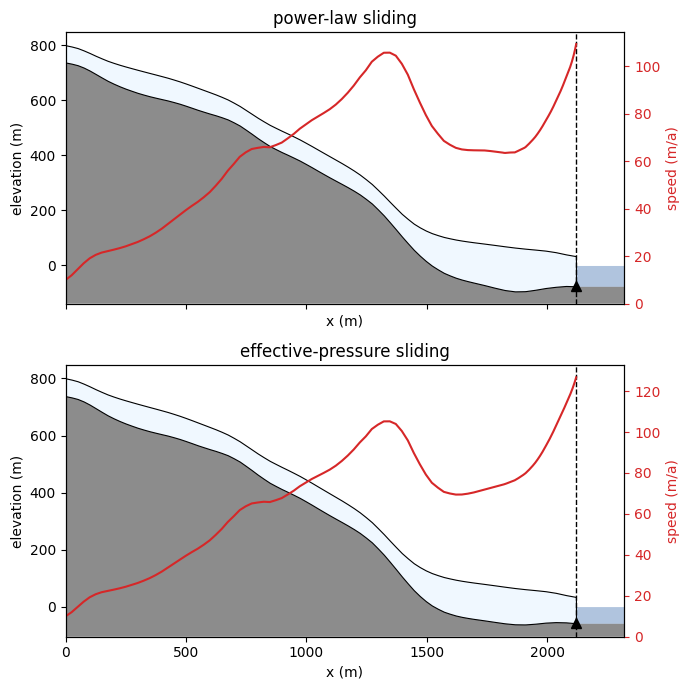

In [20]:
fig, axes = plt.subplots(2, 1, figsize = (7, 7), sharex = True)
for ax, sliding_law in zip(axes, sliding_laws):
    md, u = references[sliding_law]['md'], references[sliding_law]['u']
    plot_geometry(md, ax = ax, title = f'{sliding_law} sliding')
    ax.set_xlim(0, L_L + 200)
    x_p, speed = profile(md, depth_average(md, u[0]))
    ice = x_p <= L_L
    ax2 = ax.twinx()
    ax2.plot(x_p[ice], speed[ice], color = 'C3')
    ax2.set_ylim(0, None)
    ax2.set_ylabel('speed (m/a)', color = 'C3')
    ax2.tick_params(axis = 'y', colors = 'C3')
plt.tight_layout()
plt.show()

## Lake-level perturbations

In [21]:
for sliding_law in sliding_laws:
    reference = references[sliding_law]
    for calving_law in calving_laws:
        r = saved_L.setdefault((sliding_law, calving_law), {'L': [], 'u_t': [], 'flux': []})
        for offset in tqdm.tqdm(offsets[len(r['L']):], desc = f'{sliding_law}, {calving_law}'):
            md = flowline_mesh(model(), x_nodes_L)
            md = initialize_model(md, bed = reference['bed'], thickness = reference['H'], spcthickness = dirichlet(md, (x == 0, reference['H'])), **params_L)
            L, u_t, flux = perturbation_run(md, sliding_law, C_L, calving_law, offset, reference['k'], reference['f_star'], Δt_L)
            r['L'].append(L)
            r['u_t'].append(u_t)
            r['flux'].append(flux)
            np.save(save_file_L, saved_L)

power-law, rate law:   0%|          | 0/21 [00:00<?, ?it/s]

power-law, rate law:   5%|▍         | 1/21 [01:26<28:56, 86.81s/it]

power-law, rate law:  10%|▉         | 2/21 [02:53<27:27, 86.71s/it]

power-law, rate law:  14%|█▍        | 3/21 [04:19<25:58, 86.57s/it]

power-law, rate law:  19%|█▉        | 4/21 [05:43<24:14, 85.55s/it]

...

effective-pressure, trivial law:  86%|████████▌ | 18/21 [17:51<03:01, 60.62s/it]

effective-pressure, trivial law:  90%|█████████ | 19/21 [18:52<02:01, 60.92s/it]

effective-pressure, trivial law:  95%|█████████▌| 20/21 [19:54<01:01, 61.28s/it]

effective-pressure, trivial law: 100%|██████████| 21/21 [20:57<00:00, 61.61s/it]

effective-pressure, trivial law: 100%|██████████| 21/21 [20:57<00:00, 59.87s/it]

## Figure 3: Luggye's response to the lake level

Changes relative to the unperturbed run.

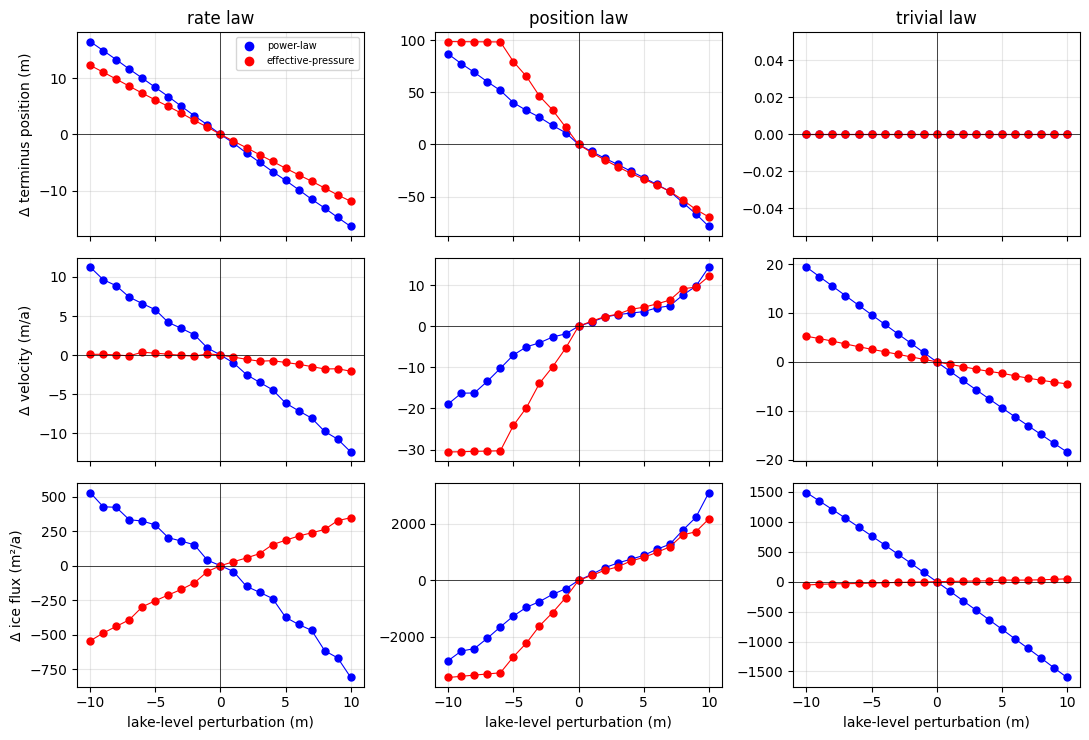

In [22]:
fig, axes = plt.subplots(3, 3, figsize = (11, 7.5), sharex = True)
for j, calving_law in enumerate(calving_laws):
    for sliding_law in sliding_laws:
        r = saved_L[(sliding_law, calving_law)]
        for i, key in enumerate(['L', 'u_t', 'flux']):
            y = np.array(r[key])
            axes[i, j].plot(offsets, y - y[offsets == 0], color = colors[sliding_law], marker = 'o', markersize = 5, linewidth = 0.8)
    axes[0, j].set_title(calving_law)
    axes[2, j].set_xlabel('lake-level perturbation (m)')
for i, label in enumerate(['Δ terminus position (m)', 'Δ velocity (m/a)', 'Δ ice flux (m²/a)']):
    axes[i, 0].set_ylabel(label)
for ax in axes.ravel():
    ax.axhline(0, color = 'k', linewidth = 0.5)
    ax.axvline(0, color = 'k', linewidth = 0.5)
    ax.grid(alpha = 0.3)
axes[0, 0].legend(handles = [Line2D([], [], color = colors[s], marker = 'o', linewidth = 0, label = s) for s in sliding_laws], fontsize = 7)
plt.tight_layout()
plt.show()

# Luggye Glacier in plan view

Luggye in plan view, with the same choices as the flowline: the drone DEM, the lake level, $C$, the inflow speed and the flowline's inverted bed, now on the glacier's outline. The domain is the glacier outline (the RGI 7.0 outline cut by the DEM, extended into the lake) clipped to the DEM's coverage; the terminus is the front mapped from imagery of 20 October 2025, two days after the DEM, rounded to the mesh (the outermost vertices upstream of it form the front). Ice enters across the top of the DEM where the consensus thickness (Farinotti et al., 2019) counts it as glacier, about 480 m of it, at 10 m/a in the middle (the flowline's inflow speed), falling to zero at either end as a parabola, and is frozen to the valley sides everywhere else. The rest of the top edge is a flat bench outside the consensus glacier, and the domain also meets the edge of the DEM where a small tributary joins from the east, through a notch about 150 m long. Both are closed: ice pushed into them piles up (on the bench it barely flows, in the notch it has nowhere to go), and a bed inversion in plan view runs away there. The front moves as in the idealized plan view. With 8 processes on Snellius, this part takes about 7 hours (the calibration about 1, the lake-level runs about 6).

## Data and parameters

In [23]:
outline_file = data_dir + '/exp_files/DomainOutline_20260126_162319.exp' #glacier outline, extended into the lake (UTM 45N)
thickness_file = data_dir + '/bed/thickness_RGI60-15.02373.tif' #consensus ice thickness (Farinotti et al., 2019): where ice enters
terminus_lonlat = [(90.31877330330583, 28.09807611129586), (90.31919172791216, 28.098104504384743), (90.31958869484636, 28.0979909319842),
                   (90.31985691574785, 28.09783950192981), (90.32003930596086, 28.097602892042097), (90.32007149246904, 28.097356817205473),
                   (90.3201358654854, 28.097176992929565), (90.32029679802629, 28.096940381581167), (90.32055429009172, 28.09669430522543),
                   (90.32076886681291, 28.096438763797273), (90.32100490120622, 28.096154828163456), (90.32110146073076, 28.095889820894154),
                   (90.32110146073076, 28.095539631713223), (90.32101563004228, 28.095113724412702)] #terminus on 20 October 2025 (GEEDiT)

h_fine, h_coarse = 10, 50 #element sizes (m): at the terminus and elsewhere
r_fine, r_grade = 80, 250 #elements are finest within r_fine of the terminus and coarsen over r_grade (m)
smoothing = 3 #width of the Gaussian smoothing of the DEM (pixels), as the flowline smooths its profile
offsets_L2 = offsets #lake-level perturbations in plan view (m)

## Domain and meshes

`luggye_mesh` meshes the domain with `bamg`, refined around the terminus; `luggye_fields` puts the data on a mesh: the observed surface relative to the lake, the consensus thickness, the ice level set (the signed distance to the terminus, negative upstream, zero on the vertices of the front; a front vertex that belongs to no element with ice is ice-free, as ISSM treats it), the inflow and the valley sides, and the inward direction of the inflow.

In [24]:
from bamg import bamg
from shapely.geometry import Polygon, LineString, Point, shape
from shapely.ops import split
from shapely import points, distance as shapely_distance, contains_xy
from rasterio.features import shapes
import rasterio.warp
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components

lines = [l for l in open(outline_file).read().splitlines() if not l.startswith('#')]
outline = Polygon(np.array([[float(v) for v in l.split()] for l in lines[1:] if l.strip()]))
with rasterio.open(dem_path) as dem:
    z_dem = dem.read(1, masked = True).astype(float).filled(np.nan)
    valid = np.isfinite(z_dem)
    coverage = max((shape(g) for g, v in shapes(valid.astype(np.uint8), mask = valid, transform = dem.transform) if v == 1), key = lambda g: g.area)
    pixel, dem_transform, dem_crs = dem.res[0], dem.transform, dem.crs
domain = outline.intersection(coverage.buffer(-pixel/2))
domain = (max(domain.geoms, key = lambda g: g.area) if domain.geom_type == 'MultiPolygon' else domain).simplify(5)

#the DEM smoothed, with gaps filled from the nearest data first (the domain lies inside the data, so this only matters at its edge)
filled = z_dem[tuple(scipy.ndimage.distance_transform_edt(~valid, return_distances = False, return_indices = True))]
z_smooth = scipy.ndimage.gaussian_filter(filled, smoothing)

terminus = LineString(gpd.GeoSeries([LineString(terminus_lonlat)], crs = 'EPSG:4326').to_crs(metric_crs).iloc[0].coords)
c_t = np.array(terminus.coords)
ends = [c_t[0] + (c_t[0] - c_t[1])/np.linalg.norm(c_t[0] - c_t[1])*500, c_t[-1] + (c_t[-1] - c_t[-2])/np.linalg.norm(c_t[-1] - c_t[-2])*500]
cutter = LineString(np.vstack([ends[0], c_t, ends[1]])) #the terminus, extended across the domain
ice_part = sorted(split(domain, cutter).geoms, key = lambda g: -g.centroid.y)[0] #upstream of the terminus (the glacier flows south)
W_L = terminus.length #length of the observed terminus (m), for lengths and fluxes per unit width
def continued(l): #a line, continued 500 m into the lake, as points every metre
    c = np.array(l.coords)
    l = LineString(np.vstack([c, c[-1] + (c[-1] - c[-2])/np.linalg.norm(c[-1] - c[-2])*500]))
    return np.array([l.interpolate(v).coords[0] for v in np.arange(0, l.length, 1.0)])
paths_L2 = [continued(line.offset_curve(d)) for d in np.arange(-100, 101, 10)] #the flowline and lines within 100 m of it: the terminus speed is averaged over where they meet the front

def luggye_mesh(h_terminus):
    outer = np.array(domain.exterior.coords)
    md = bamg(model(), 'domain', [{'x': outer[:, 0], 'y': outer[:, 1], 'nods': len(outer), 'closed': 1, 'density': 1, 'name': 'domain', 'Geometry': 'Polygon'}],
              'hmax', h_coarse)
    for refinement in range(2):
        d = shapely_distance(points(md.mesh.x, md.mesh.y), terminus)
        h = np.clip(h_terminus + (h_coarse - h_terminus)*np.clip((d - r_fine)/r_grade, 0, 1), h_terminus, h_coarse)
        md = bamg(md, 'hVertices', h, 'hmax', h_coarse, 'hmin', h_terminus)
    return md

def luggye_fields(md):
    x, y = md.mesh.x, md.mesh.y
    elements = md.mesh.elements.astype(int) - 1
    cols, rows = ~dem_transform*(x, y) #fractional pixel positions
    s = scipy.ndimage.map_coordinates(z_smooth, [rows - 0.5, cols - 0.5], order = 1, mode = 'nearest') - lake_level #bilinear, between pixel centres
    with rasterio.open(thickness_file) as r:
        xs, ys = rasterio.warp.transform(metric_crs, r.crs, x, y)
        H_consensus = np.nan_to_num(np.array([v[0] for v in r.sample(zip(xs, ys), masked = True)], dtype = float))
    ice = contains_xy(ice_part.buffer(1e-6), x, y)
    φ = shapely_distance(points(x, y), cutter)*np.where(ice, -1., 1.)
    cut = np.any(ice[elements], axis = 1) & np.any(~ice[elements], axis = 1)
    front = np.zeros(x.size, dtype = bool)
    front[elements[cut].ravel()] = True
    front &= ice
    φ[front] = 0. #the front on the outermost ice vertices
    ice_elements = np.min(φ[elements], axis = 1) < 0 #as ISSM counts them
    alone = ice & ~np.isin(np.arange(x.size), elements[ice_elements]) #front vertices in no element with ice: ice-free
    φ[alone], ice[alone], front[alone] = np.abs(φ[alone]) + 1e-3, False, False
    segments = md.mesh.segments.astype(int)[:, :2] - 1
    boundary = np.zeros(x.size, dtype = bool)
    boundary[segments.ravel()] = True
    inflow = boundary & ice & (shapely_distance(points(x, y), coverage.exterior) < 2*pixel) & (s > 200) & (H_consensus > 0)
    #the inflow: the longest stretch of boundary on the edge of the DEM (its top) that the consensus counts as glacier, at u_in_L in the
    #middle, falling to zero at its ends as a parabola; the rest of the top edge (a flat bench outside the consensus glacier, where ice
    #pushed in piles up) and shorter stretches (the tributary's narrow notch, where it has nowhere to go) are valley sides
    stretches = segments[inflow[segments[:, 0]] & inflow[segments[:, 1]]]
    label = connected_components(coo_matrix((np.ones(len(stretches)), tuple(stretches.T)), shape = (x.size, x.size)), directed = False)[1]
    paths = []
    for c in np.unique(label[inflow]):
        members = np.flatnonzero(inflow & (label == c))
        neighbours = {v: [b if a == v else a for a, b in stretches if v in (a, b)] for v in members}
        order = [next((v for v in members if len(neighbours[v]) == 1), members[0])] #from one end along the stretch
        while next_vertex := [v for v in neighbours[order[-1]] if v not in order]:
            order.append(next_vertex[0])
        paths.append((np.r_[0, np.cumsum(np.hypot(np.diff(x[order]), np.diff(y[order])))], order))
    arc, order = max(paths, key = lambda p: p[0][-1])
    inflow_speed = np.zeros(x.size)
    inflow_speed[order] = u_in_L*(1 - (2*arc/arc[-1] - 1)**2)
    inflow &= inflow_speed > 0 #the ends of the stretch are frozen to the sides
    sides = boundary & ~inflow
    normal = np.zeros((x.size, 2)) #inward normal on the boundary
    for a, b in segments:
        n = np.array([y[a] - y[b], x[b] - x[a]])/np.hypot(x[b] - x[a], y[b] - y[a])
        if not domain.buffer(1e-3).contains(Point((x[a] + x[b])/2 + 1e-2*n[0], (y[a] + y[b])/2 + 1e-2*n[1])):
            n = -n
        normal[a] += n
        normal[b] += n
    normal /= np.maximum(np.linalg.norm(normal, axis = 1), 1e-12)[:, None]
    return SimpleNamespace(x = x, y = y, s = s, H_consensus = H_consensus, ice_levelset = φ, ice = ice, front = front,
                           inflow = inflow, sides = sides, spcvx = dirichlet(md, (inflow, inflow_speed*normal[:, 0]), (sides, 0)),
                           spcvy = dirichlet(md, (inflow, inflow_speed*normal[:, 1]), (sides, 0)))

md_L2 = luggye_mesh(h_fine)
fields_L2 = luggye_fields(md_L2)
print(f'mesh: {md_L2.mesh.numberofvertices} vertices, {fields_L2.front.sum()} on the front; terminus {W_L:.0f} m long')

could not import shapefile, PyShp has not been installed, no shapefile reading capabilities enabled


At least one contour was not correctly oriented and has been re-oriented


mesh: 2669 vertices, 74 on the front; terminus 454 m long


## The bed

The plan view uses the flowline's inverted bed for each sliding law: the ice is as thick as the flowline's at the same distance along the flowline, all the way across the glacier (at least 10 m). The two models then share the bed along the flowline and the water depth at the terminus, and differ only in the second dimension. On this bed the plan-view glacier is not in balance with the observed surface either; the experiments measure changes from its unperturbed year.

A bed inverted in plan view, in the same way as the flowline's, gives no usable glacier. Inverted for a steady glacier, it converges with the terminus in about 5 m of water (power law): with no surface mass balance, a glacier in balance discharges at its front only what enters across the top of the DEM, about 390 m²/a per metre of terminus, and the observed terminus, 34 m above the lake, carries that little only when it is about 40 m thick. Inverted for a thinning glacier (uniform thinning up to the observed 4.67 m/a, or thinning falling with height from the 9.1 m/a observed lowest down to 1.3 m/a), it does not settle. With no surface mass balance, the ice can thin only by flowing, and the slow ice along the valley sides and where the steep slope meets the overdeepened tongue cannot thin at the target rate, while the lowest 300 m of the tongue thin at 8–17 m/a when the bed under them is deep. The inversion keeps lowering the bed where the ice thins too little and raises it under the tongue into a sill, with the terminus heading for 5–20 m of water.

In [25]:
settings_L2 = {'flowline': settings_L, 'outline_file': outline_file, 'thickness_file': thickness_file, 'terminus': terminus_lonlat,
               'h': (h_fine, h_coarse, r_fine, r_grade), 'smoothing': smoothing, 'bed': 'flowline',
               'offsets_L2': np.asarray(offsets_L2).tolist()} #everything the results depend on
save_file_L2 = f'GRL_luggye_2d_{hashlib.md5(str(settings_L2).encode()).hexdigest()[:8]}.npy'
saved_L2 = np.load(save_file_L2, allow_pickle = True).item() if os.path.exists(save_file_L2) else {}
save_L2 = lambda: np.save(save_file_L2, saved_L2)
print('progress file:', save_file_L2)

params_L2 = {'approximation': 'HO', 'vertical_layers': vertical_layers, 'temperature': T, 'friction': C_L, 'm': m, 'rho_water': ρ_w}

def new_model_L2(md_mesh, fields, bed, H, calving_law, velocity = (0, 0)):
    md = copy.deepcopy(md_mesh)
    md.cluster.np = n_proc
    return initialize_model(md, bed = bed, thickness = H, ice_levelset = fields.ice_levelset, moving_front = calving_law != 'trivial law',
                            velocity = velocity, spcvx = fields.spcvx, spcvy = fields.spcvy, spcthickness = dirichlet(md, (fields.inflow, H)), **params_L2)

def flowline_bed(fields, sliding_law): #the flowline's inverted bed: its thickness at the same distance along the flowline, across the glacier
    along = np.array([line.project(Point(px, py)) for px, py in zip(fields.x, fields.y)])
    return fields.s - np.maximum(np.interp(along, x_L, s_obs - saved_L[('bed', sliding_law)]), 10)

progress file: GRL_luggye_2d_67f8bced.npy


## Reference state and calibration

The observed surface on the flowline's bed, with the lake floor beyond the terminus at the depth of the nearest point of the front. $k$ and $f^*$ are calibrated for zero change in ice area over the unperturbed year, starting from $k$ = mean speed at the front / mean water depth there and $f^*$ = the lowest $f_{af}$ along the front (where the position law would calve first). Lengths and fluxes are per unit length of the observed terminus. Each calibration try is saved as it is made, so a restart replays them.

In [26]:
from scipy.spatial import cKDTree

f = fields_L2
references_L2 = {}
for sliding_law in sliding_laws:
    bed = flowline_bed(f, sliding_law)
    lake = ~f.ice
    bed[lake] = bed[f.front][cKDTree(np.c_[f.x[f.front], f.y[f.front]]).query(np.c_[f.x[lake], f.y[lake]])[1]]
    H = np.where(f.ice, np.maximum(f.s - bed, 1), 0)

    if ('calibration', sliding_law) not in saved_L2:
        #the reference state's front, the starting guesses and every calibration try, kept so that a restart replays them
        reference = saved_L2.setdefault(('reference', sliding_law), {})
        if 'k_0' not in reference:
            md = new_model_L2(md_L2, f, bed, H, 'trivial law')
            u = diagnostic_solve(md, friction = friction(md, sliding_law, C_L))
            fd = front_diagnostics(md)
            f_af = (md.geometry.base[:md.mesh.numberofvertices2d] - 0 + ϱ*H)/np.maximum(H, 1)
            reference.update({'velocity': (depth_average(md, u[0]), depth_average(md, u[1])), 'area': fd.area, 'depth': np.mean((0 - bed)[f.front]),
                              'thickness': np.mean(H[f.front]), 'speed': fd.speed, 'k tries': {}, 'f* tries': {}})
            reference.update({'k_0': fd.speed/reference['depth'], 'f_0': np.min(f_af[f.front])})
            save_L2()
        new_model = lambda law, bed = bed, H = H, velocity = reference['velocity']: new_model_L2(md_L2, f, bed, H, law, velocity)

        def drift(calving_law, k, f_star): #how far the mean terminus position moves in the unperturbed run (m)
            return perturbation_run_2d(new_model, sliding_law, C_L, calving_law, 0, k, f_star, Δt_L, W_L, paths_L2)[0] - reference['area']/W_L
        k, drift_k = calibrate(remembered(lambda k: drift('rate law', k, None), reference['k tries'], save_L2),
                               reference['k_0'], 0.05*reference['k_0'], f'{sliding_law}: k')
        f_star, drift_f = calibrate(remembered(lambda f_star: drift('position law', None, f_star), reference['f* tries'], save_L2),
                                    reference['f_0'], 0.005, f'{sliding_law}: f*')
        saved_L2[('calibration', sliding_law)] = {'k': k, 'f_star': f_star, 'k_0': reference['k_0'], 'f_0': reference['f_0'], 'drift_k': drift_k,
                                                  'drift_f': drift_f, 'velocity': reference['velocity'], 'depth': reference['depth'],
                                                  'thickness': reference['thickness'], 'speed': reference['speed']}
        save_L2()

    c = saved_L2[('calibration', sliding_law)]
    new_model = lambda law, bed = bed, H = H, velocity = c['velocity']: new_model_L2(md_L2, f, bed, H, law, velocity)
    references_L2[sliding_law] = {'bed': bed, 'H': H, 'model': new_model, 'k': c['k'], 'f_star': c['f_star']}
    print(f'{sliding_law}: front in {c["depth"]:.0f} m of water, {c["thickness"]:.0f} m thick, at {c["speed"]:.1f} m/a (means along it); '
          f'k = {c["k_0"]:.3f} -> {c["k"]:.3f} /a (drift {c["drift_k"]:+.2f} m), f* = {c["f_0"]:.3f} -> {c["f_star"]:.3f} ({c["drift_f"]:+.2f} m)')

power-law: k = 0.8713: terminus drift -3.12 m


power-law: k = 0.8278: terminus drift +0.68 m


power-law: k = 0.8356: terminus drift -0.02 m


power-law: f* = 0.1586: terminus drift +39.16 m


power-law: f* = 0.1636: terminus drift +34.53 m


...

effective-pressure: f* = 0.2037: terminus drift +45.72 m


effective-pressure: f* = 0.2087: terminus drift +39.69 m


effective-pressure: f* = 0.2287: terminus drift +21.72 m


effective-pressure: f* = 0.2528: terminus drift -2.87 m


effective-pressure: f* = 0.2500: terminus drift -0.12 m
effective-pressure: front in 59 m of water, 94 m thick, at 80.3 m/a (means along it); k = 1.367 -> 1.299 /a (drift +0.18 m), f* = 0.204 -> 0.250 (-0.12 m)


## Figure 6: Luggye in plan view

For each sliding law, the bed relative to the lake (left) and the depth-averaged speed of the reference state (right), with the front (black) and the flowline (white).

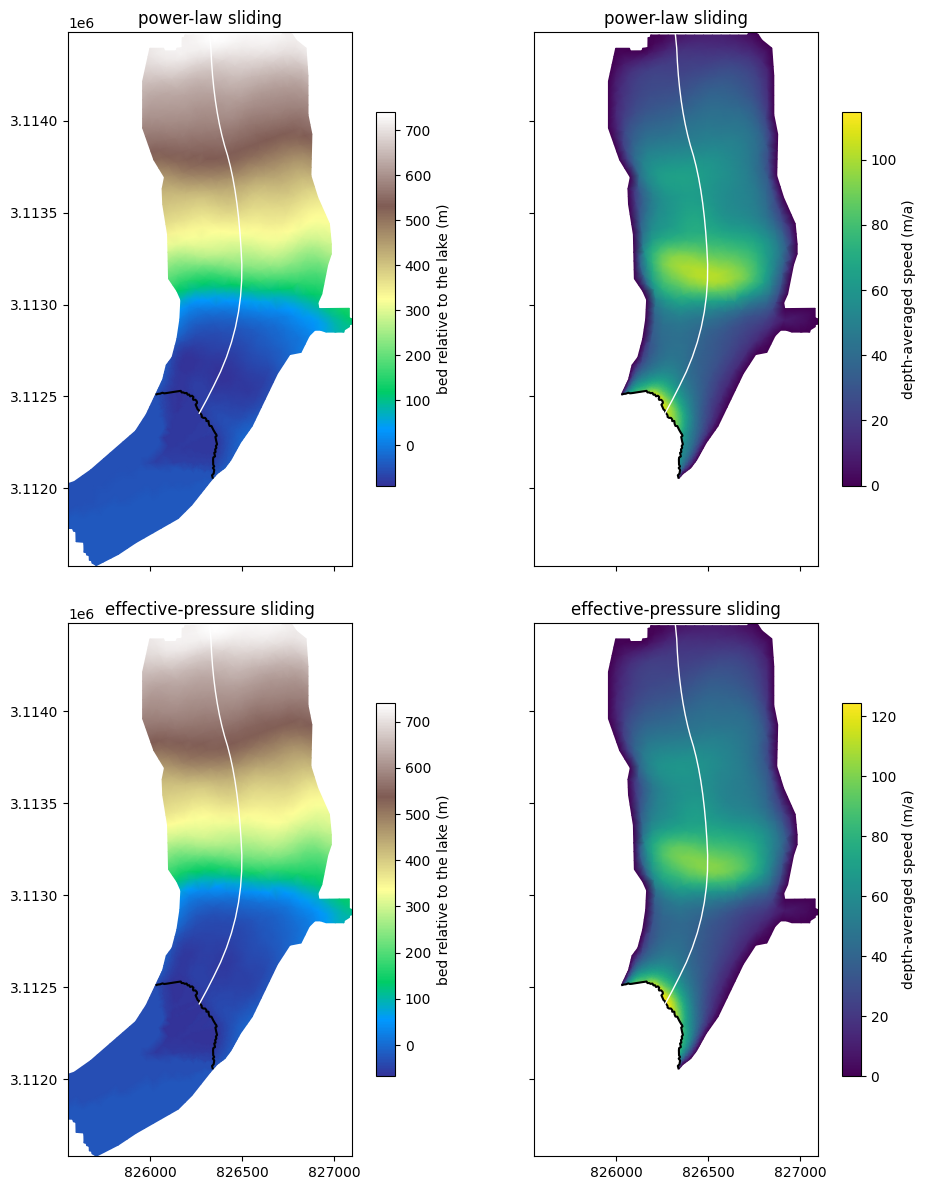

In [27]:
fig, axes = plt.subplots(2, 2, figsize = (10, 12), sharex = True, sharey = True)
elements = md_L2.mesh.elements - 1
for i, sliding_law in enumerate(sliding_laws):
    ref = references_L2[sliding_law]
    md = ref['model']('trivial law')
    u = diagnostic_solve(md, friction = friction(md, sliding_law, C_L))
    speed = np.hypot(depth_average(md, u[0]), depth_average(md, u[1]))
    ice = np.max(fields_L2.ice_levelset[elements], axis = 1) <= 0
    for ax, field, cmap, label, triangles in [(axes[i, 0], ref['bed'], 'terrain', 'bed relative to the lake (m)', elements),
                                              (axes[i, 1], speed, 'viridis', 'depth-averaged speed (m/a)', elements[ice])]:
        image = ax.tripcolor(fields_L2.x, fields_L2.y, triangles, field, shading = 'gouraud', cmap = cmap)
        ax.tricontour(fields_L2.x, fields_L2.y, elements, fields_L2.ice_levelset, levels = [0], colors = 'k', linewidths = 1.5)
        ax.plot(*np.array(line.coords).T, color = 'white', linewidth = 1)
        ax.set_aspect('equal')
        ax.set_title(f'{sliding_law} sliding')
        fig.colorbar(image, ax = ax, label = label, shrink = 0.7)
plt.tight_layout()
plt.show()

## Lake-level perturbations in plan view

In [28]:
for sliding_law in sliding_laws:
    reference = references_L2[sliding_law]
    for calving_law in calving_laws:
        r = saved_L2.setdefault((sliding_law, calving_law), {'L': [], 'u_t': [], 'flux': []})
        for offset in tqdm.tqdm(offsets_L2[len(r['L']):], desc = f'{sliding_law}, {calving_law}'):
            L, u_t, flux = perturbation_run_2d(reference['model'], sliding_law, C_L, calving_law, offset,
                                               reference['k'], reference['f_star'], Δt_L, W_L, paths_L2)
            r['L'].append(L)
            r['u_t'].append(u_t)
            r['flux'].append(flux)
            np.save(save_file_L2, saved_L2)

power-law, rate law:   0%|          | 0/21 [00:00<?, ?it/s]

power-law, rate law:   5%|▍         | 1/21 [03:30<1:10:03, 210.17s/it]

power-law, rate law:  10%|▉         | 2/21 [06:59<1:06:26, 209.80s/it]

power-law, rate law:  14%|█▍        | 3/21 [10:28<1:02:51, 209.51s/it]

power-law, rate law:  19%|█▉        | 4/21 [13:58<59:20, 209.43s/it]  

...

effective-pressure, trivial law:  86%|████████▌ | 18/21 [34:26<05:45, 115.24s/it]

effective-pressure, trivial law:  90%|█████████ | 19/21 [36:22<03:50, 115.40s/it]

effective-pressure, trivial law:  95%|█████████▌| 20/21 [38:18<01:55, 115.59s/it]

effective-pressure, trivial law: 100%|██████████| 21/21 [40:15<00:00, 115.87s/it]

effective-pressure, trivial law: 100%|██████████| 21/21 [40:15<00:00, 115.01s/it]

## Figure 7: Luggye's response to the lake level, flowline and plan view

Changes relative to the unperturbed run, for the flowline (open markers, dashed) and the plan view (filled markers, solid). Velocity is the terminus speed (for the plan view, the mean over the front within 100 m of the flowline); the flux is per metre of the observed terminus.

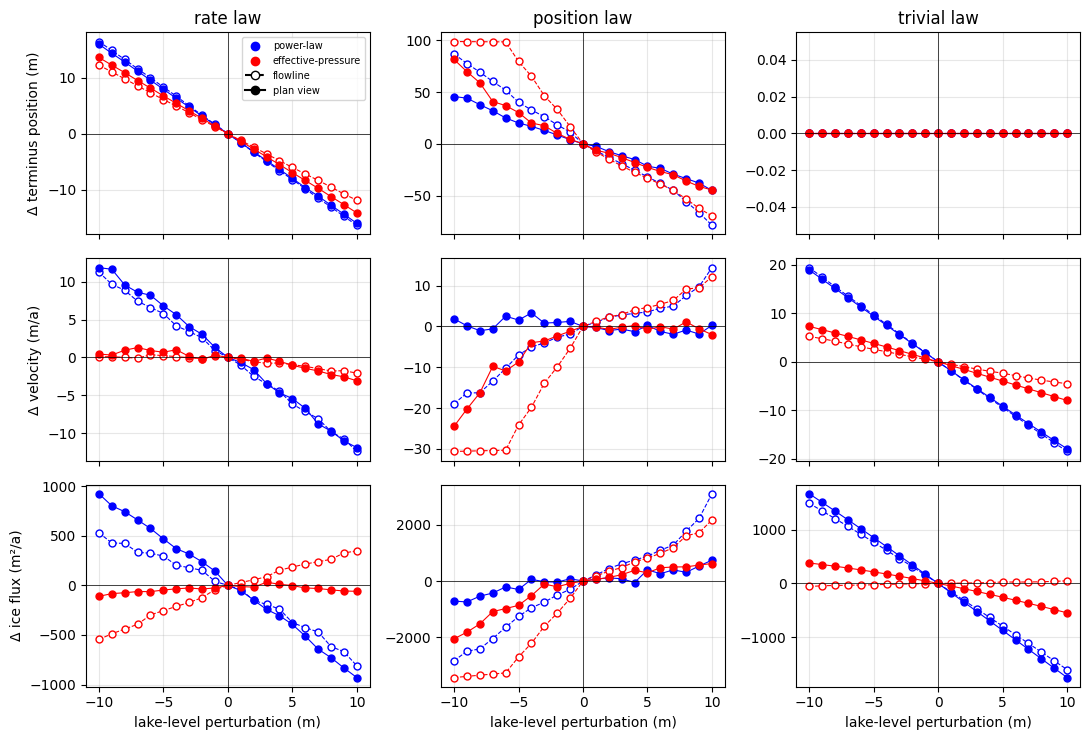

In [29]:
fig, axes = plt.subplots(3, 3, figsize = (11, 7.5), sharex = True)
for j, calving_law in enumerate(calving_laws):
    for sliding_law in sliding_laws:
        for results, x_off, style in [(saved_L, offsets, dict(linestyle = 'dashed', markerfacecolor = 'white')),
                                      (saved_L2, np.asarray(offsets_L2), dict(linestyle = 'solid'))]:
            r = results[(sliding_law, calving_law)]
            for i, key in enumerate(['L', 'u_t', 'flux']):
                y = np.array(r[key])
                axes[i, j].plot(x_off, y - y[x_off == 0], color = colors[sliding_law], marker = 'o', markersize = 5, linewidth = 0.8, **style)
    axes[0, j].set_title(calving_law)
    axes[2, j].set_xlabel('lake-level perturbation (m)')
for i, label in enumerate(['Δ terminus position (m)', 'Δ velocity (m/a)', 'Δ ice flux (m²/a)']):
    axes[i, 0].set_ylabel(label)
for ax in axes.ravel():
    ax.axhline(0, color = 'k', linewidth = 0.5)
    ax.axvline(0, color = 'k', linewidth = 0.5)
    ax.grid(alpha = 0.3)
handles = [Line2D([], [], color = colors[s], marker = 'o', linewidth = 0, label = s) for s in sliding_laws]
handles += [Line2D([], [], color = 'k', marker = 'o', markerfacecolor = 'white', linestyle = 'dashed', label = 'flowline'),
            Line2D([], [], color = 'k', marker = 'o', linestyle = 'solid', label = 'plan view')]
axes[0, 0].legend(handles = handles, fontsize = 7)
plt.tight_layout()
plt.show()